In [149]:
import json
import os
import random
import re
from collections import Counter

import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns
from matplotlib.ticker import MultipleLocator

sns.set_theme(style="whitegrid", context="notebook", font_scale=1.05)
PALETTE = "Set2"

In [150]:
KB_PATH = "/Users/ddore/Documents/FallacyRAG-documents/knowledge_base"

In [151]:
os.system(f"du -sh {KB_PATH}")

 15G	/Users/ddore/Documents/FallacyRAG-documents/knowledge_base


0

In [152]:
os.system(f"ls -la {KB_PATH}")

total 24
drwxrwxr-x     10 ddore  842369102      320 Jul  9 14:16 .
drwxr-xr-x      7 ddore  842369102      224 Jul  9 14:25 ..
-rw-r--r--@     1 ddore  842369102     8196 Jul  9 14:17 .DS_Store
drwxrwxr-x  65535 ddore  842369102  5708320 May 23 07:43 bills
drwxrwxr-x     68 ddore  842369102     2176 Jun 19 20:09 definitions
drwxrwxr-x   1275 ddore  842369102    40800 Jun 19 20:09 exemplars
drwxrwxr-x  65535 ddore  842369102  4028576 Jun 19 14:15 geography
drwxrwxr-x  16123 ddore  842369102   515936 Jun 19 20:08 history
drwxrwxr-x      3 ddore  842369102       96 Jun 19 20:09 newspapers
drwxrwxr-x  65535 ddore  842369102  2334464 Jun 19 18:13 people


0

In [153]:
print("bills:")
os.system(f"du -sh {KB_PATH}/bills")

print("definitions:")
os.system(f"du -sh {KB_PATH}/definitions")

print("exemplars:")
os.system(f"du -sh {KB_PATH}/exemplars")

print("geography:")
os.system(f"du -sh {KB_PATH}/geography")

print("history:")
os.system(f"du -sh {KB_PATH}/history")

print("newspapers:")
os.system(f"du -sh {KB_PATH}/newspapers")

print("people:")
os.system(f"du -sh {KB_PATH}/people")

FOLDERS = ["bills", "definitions", "exemplars", "geography", "history", "newspapers", "people"]


bills:
 14G	/Users/ddore/Documents/FallacyRAG-documents/knowledge_base/bills
definitions:
1.3M	/Users/ddore/Documents/FallacyRAG-documents/knowledge_base/definitions
exemplars:
5.0M	/Users/ddore/Documents/FallacyRAG-documents/knowledge_base/exemplars
geography:
516M	/Users/ddore/Documents/FallacyRAG-documents/knowledge_base/geography
history:
 89M	/Users/ddore/Documents/FallacyRAG-documents/knowledge_base/history
newspapers:
 16M	/Users/ddore/Documents/FallacyRAG-documents/knowledge_base/newspapers
people:
297M	/Users/ddore/Documents/FallacyRAG-documents/knowledge_base/people


In [154]:
def peek(folder: str, n: int = 1):
    """Open the first n JSON files in a folder and print their raw structure,
    so we can see what schema each category uses (dict vs list, keys, etc.)."""
    folder_path = os.path.join(KB_PATH, folder)
    files = [f for f in os.listdir(folder_path) if f.endswith(".json")]

    for fname in files[:n]:
        fpath = os.path.join(folder_path, fname)
        with open(fpath, "r", encoding="utf-8") as fh:
            data = json.load(fh)
        print(f"--- {folder}/{fname} ---")
        print(json.dumps(data, indent=2, ensure_ascii=False)[:1000])
        print()


YEAR_RE = re.compile(r"(1[5-9]\d{2}|20\d{2})")


def extract_year(filename: str, json_data):
    """Best-effort year extraction: first from the filename, then from
    common metadata keys inside the JSON payload."""
    m = YEAR_RE.search(filename)
    if m:
        return int(m.group(1))

    if isinstance(json_data, dict):
        for key in ("year", "Year", "date", "Date", "publication_year"):
            if key in json_data:
                m2 = YEAR_RE.search(str(json_data[key]))
                if m2:
                    return int(m2.group(1))
    return None


def approx_length(json_data) -> int:
    """Rough character-count of the textual content of a document,
    regardless of whether the JSON is a dict or a list of dicts."""
    if isinstance(json_data, dict):
        return sum(len(str(v)) for v in json_data.values())
    if isinstance(json_data, list):
        return sum(len(str(item)) for item in json_data)
    return len(str(json_data))


def count(folder: str, sample_size: int = 500, seed: int = 42):
    """Report size, document count, a year histogram, and length stats
    for one knowledge-base folder.

    Some folders (e.g. bills) contain 100k+ JSON files, so instead of
    parsing every file we take a random sample (sample_size files) for
    the content-based stats (year-from-metadata, doc length). Year
    extracted from the filename itself is still checked on every file
    since that's essentially free (no I/O).
    """
    print(f"============ FOLDER: {folder.upper()} ============")

    folder_path = os.path.join(KB_PATH, folder)

    print("Total space:")
    os.system(f"du -sh {folder_path}")

    files = [f for f in os.listdir(folder_path) if f.endswith(".json")]
    print(f"Count: {len(files)} documents.")

    # Fast pass: years from filenames only, over ALL files
    filename_years = [y for f in files if (y := YEAR_RE.search(f)) is not None]
    filename_years = [int(y.group(1)) for y in filename_years]

    # Slow pass: open a random sample to get content-based years + lengths
    rng = random.Random(seed)
    sample_files = rng.sample(files, min(sample_size, len(files)))

    sampled_years = []
    sampled_lengths = []
    parse_errors = 0

    for fname in sample_files:
        fpath = os.path.join(folder_path, fname)
        try:
            with open(fpath, "r", encoding="utf-8") as fh:
                json_data = json.load(fh)
        except (json.JSONDecodeError, UnicodeDecodeError):
            parse_errors += 1
            continue

        year = extract_year(fname, json_data)
        if year:
            sampled_years.append(year)
        sampled_lengths.append(approx_length(json_data))

    years = filename_years if filename_years else sampled_years

    if years:
        year_counts = Counter(years)
        print(f"Year range: {min(years)}-{max(years)}  (n={len(years)} with a detected year)")
        for y in sorted(year_counts):
            print(f"  {y}: {year_counts[y]}")
    else:
        print("No year information found in filenames or sampled document content.")

    if sampled_lengths:
        lengths = pd.Series(sampled_lengths)
        print(f"\nDocument length (characters), sampled n={len(sampled_lengths)}:")
        print(lengths.describe())

    if parse_errors:
        print(f"\n[!] {parse_errors}/{len(sample_files)} sampled files failed to parse.")

    print("=" * 50)

    return {
        "folder": folder,
        "n_docs": len(files),
        "years": years,
        "sample_lengths": sampled_lengths,
        "parse_errors": parse_errors,
    }

In [155]:
# Look at the raw shape of one document per folder before aggregating,
# since "bills" and "people" etc. may use different JSON schemas.
for folder in FOLDERS:
    peek(folder, n=1)

--- bills/USCODE-2024-title29-chap8-sec206_15.json ---
{
  "id": "USCODE-2024-title29-chap8-sec206",
  "text": "U. S.C. Title 29 - LABOR 29 U. S.C. United States Code, 2024 Edition Title 29 - LABOR CHAPTER 8 - FAIR LABOR STANDARDS Sec. 206 - Minimum wage From the U. S. Government Publishing Office, www. gpo. gov 206. Minimum wage (a) Employees engaged in commerce; home workers in Puerto Rico and Virgin Islands; employees in American Samoa; seamen on American vessels; agricultural employees Every employer shall pay to each of his employees who in any workweek is engaged in commerce or in the production of goods for commerce, or is employed in an enterprise engaged in commerce or in the production of goods for commerce, wages at the following rates: (1) except as otherwise provided in this section, not less than (A) $5.85 an hour, beginning on the 60th day after May 25, 2007; (B) $6.55 an hour, beginning 12 months after that 60th day; and (C) $7.25 an hour, beginning 24 months after that

In [141]:
summary = [count(folder) for folder in FOLDERS]

============ FOLDER: BILLS ============
Total space:
 14G	/Users/ddore/Documents/FallacyRAG-documents/knowledge_base/bills
Count: 178383 documents.
Year range: 1502-2095  (n=134680 with a detected year)
  1502: 5
  1503: 15
  1504: 15
  1506: 40
  1508: 5
  1511: 20
  1513: 5
  1514: 10
  1515: 10
  1517: 5
  1518: 5
  1520: 5
  1522: 15
  1523: 10
  1527: 25
  1528: 5
  1529: 10
  1531: 15
  1532: 10
  1535: 5
  1538: 10
  1539: 5
  1541: 5
  1542: 20
  1544: 10
  1545: 5
  1546: 15
  1551: 10
  1552: 5
  1553: 20
  1556: 15
  1558: 5
  1559: 20
  1560: 5
  1562: 20
  1563: 20
  1565: 5
  1567: 10
  1568: 35
  1569: 30
  1570: 5
  1571: 5
  1574: 10
  1575: 5
  1577: 10
  1578: 5
  1579: 5
  1581: 15
  1582: 25
  1583: 5
  1586: 5
  1587: 5
  1588: 5
  1589: 15
  1590: 10
  1591: 5
  1593: 25
  1595: 20
  1600: 10
  1601: 5
  1603: 10
  1604: 5
  1605: 5
  1607: 15
  1609: 5
  1610: 5
  1611: 20
  1612: 5
  1613: 15
  1614: 5
  1618: 5
  1620: 5
  1624: 5
  1625: 5
  1627: 10
  1628: 

In [142]:
summary_df = pd.DataFrame([
    {
        "folder": s["folder"],
        "n_docs": s["n_docs"],
        "n_docs_with_year": len(s["years"]),
        "year_min": min(s["years"]) if s["years"] else None,
        "year_max": max(s["years"]) if s["years"] else None,
        "avg_length_chars_sampled": (
            sum(s["sample_lengths"]) / len(s["sample_lengths"])
            if s["sample_lengths"] else None
        ),
        "sample_parse_errors": s["parse_errors"],
    }
    for s in summary
])
summary_df

,folder,n_docs,n_docs_with_year,year_min,year_max,avg_length_chars_sampled,sample_parse_errors
0,bills,178383,134680,1502.0,2095.0,71043.738000,0
1,definitions,65,65,1900.0,1900.0,8561.676923,0
2,exemplars,1273,261,1500.0,2091.0,339.936000,0
3,geography,125891,5274,1500.0,2089.0,1122.940000,0
4,history,16121,3903,1776.0,2034.0,2378.386000,0
5,newspapers,0,0,NaN,NaN,NaN,0
6,people,72950,4939,1563.0,2077.0,996.750000,0


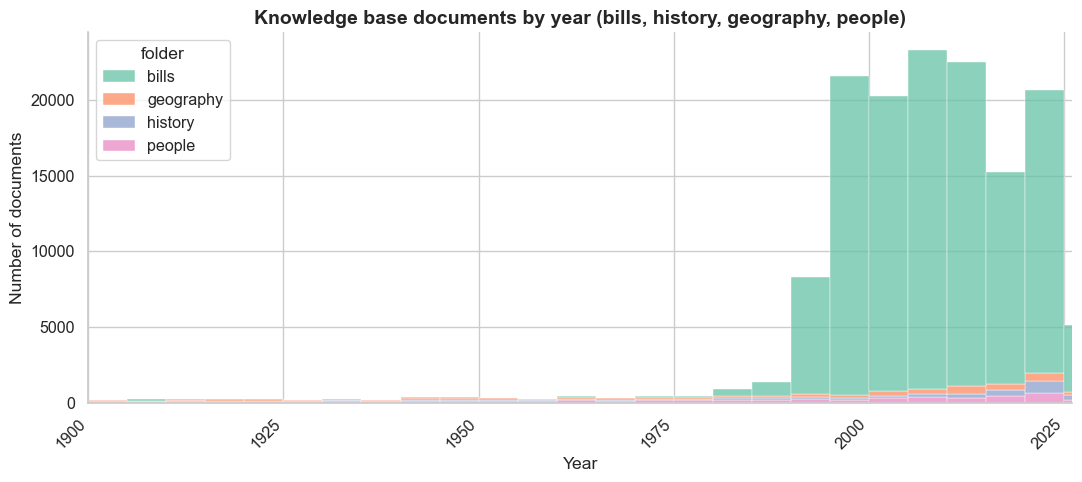

In [143]:
PLOT_FOLDERS = ["bills", "history", "geography", "people"]

all_years_records = [
    {"folder": s["folder"], "year": y}
    for s in summary if s["folder"] in PLOT_FOLDERS
    for y in s["years"]
]

if all_years_records:
    years_df = pd.DataFrame(all_years_records)

    plt.figure(figsize=(11, 5))
    ax = sns.histplot(
        data=years_df,
        x="year",
        hue="folder",
        multiple="stack",
        palette=PALETTE,
        edgecolor="white",
        linewidth=0.3,
        binwidth=5,
    )
    ax.set_title("Knowledge base documents by year (bills, history, geography, people)", fontsize=14, fontweight="bold")
    ax.set_xlabel("Year")
    ax.set_ylabel("Number of documents")

    # show intermediate year ticks, not just the endpoints
    ax.xaxis.set_major_locator(MultipleLocator(25))
    plt.xticks(rotation=45, ha="right")
    ax.set_xlim((1900, 2026))

    sns.despine()
    plt.tight_layout()
    plt.show()
else:
    print("No year data available to plot.")

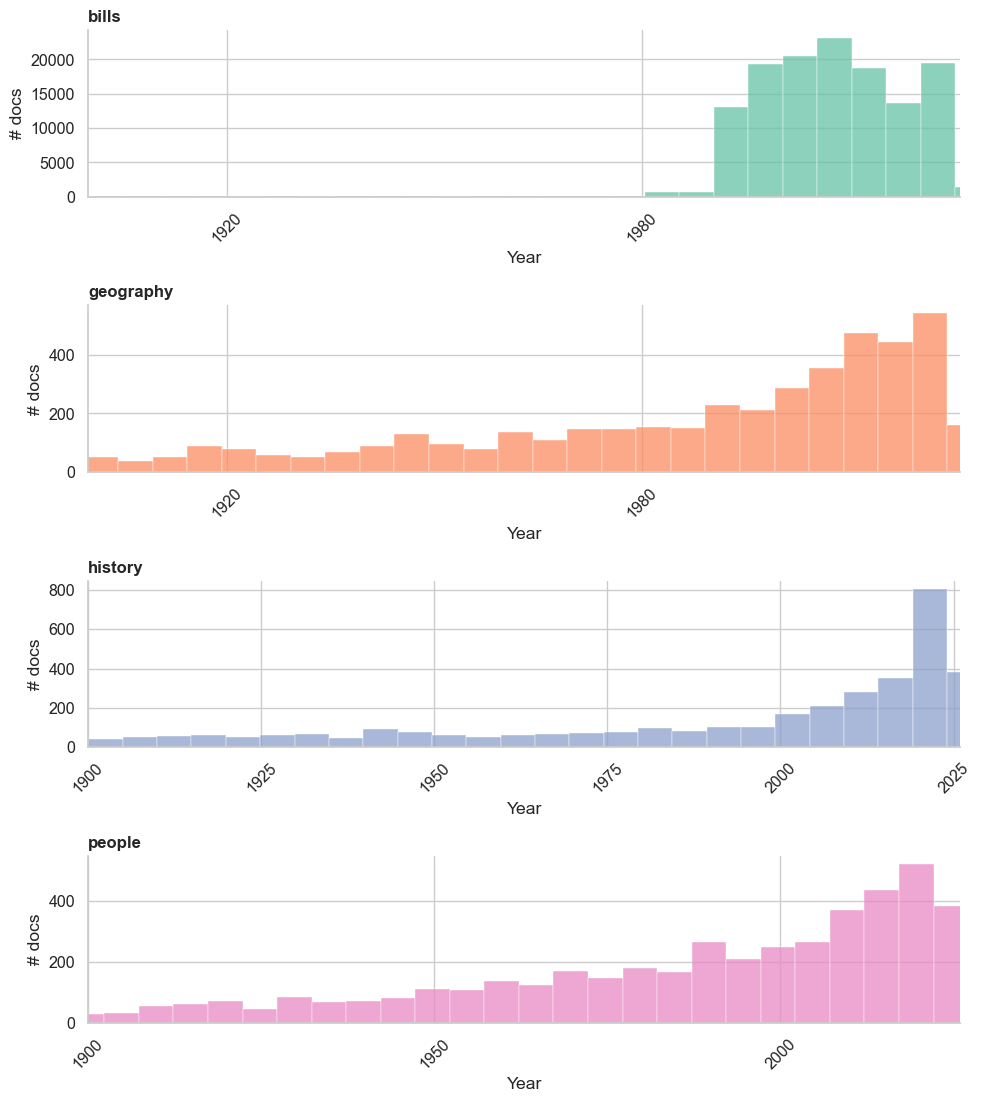

In [144]:
PLOT_FOLDERS = ["bills", "history", "geography", "people"]

folders_with_years = [s for s in summary if s["folder"] in PLOT_FOLDERS and s["years"]]

if folders_with_years:
    n = len(folders_with_years)
    colors = sns.color_palette(PALETTE, n_colors=n)

    fig, axes = plt.subplots(n, 1, figsize=(10, 2.8 * n), sharex=False)
    if n == 1:
        axes = [axes]

    for ax, s, color in zip(axes, folders_with_years, colors):
        ys = s["years"]
        y_min, y_max = min(ys), max(ys)
        # histplot errors on a zero-width range (e.g. every doc has the same
        # year), so pad the bin range when there's no spread in the data.
        binrange = (y_min - 2, y_max + 3) if y_min == y_max else (y_min, y_max)

        sns.histplot(
            ys, binwidth=5, binrange=binrange,
            color=color, edgecolor="white", linewidth=0.3, ax=ax,
        )
        ax.set_title(s["folder"], fontsize=12, fontweight="bold", loc="left")
        ax.set_xlabel("Year")
        ax.set_ylabel("# docs")

        # pick a tick step so ~8-12 ticks show up regardless of the folder's
        # year span, so intermediate years are visible (not just min/max)
        span = binrange[1] - binrange[0]
        step = max(10, round(span / 10 / 5) * 5)
        ax.xaxis.set_major_locator(MultipleLocator(step))
        ax.tick_params(axis="x", rotation=45)
        ax.set_xlim((1900, 2026))

        sns.despine(ax=ax)

    plt.tight_layout()
    plt.show()
else:
    print("No per-folder year data available to plot.")

In [146]:
from wordcloud import WordCloud, STOPWORDS

CUSTOM_STOPWORDS = set(STOPWORDS) | {"nan", "none"}


def extract_text(json_data) -> str:
    """Pull the human-readable text out of a document regardless of schema."""
    if isinstance(json_data, dict):
        if "text" in json_data and isinstance(json_data["text"], str):
            return json_data["text"]
        return " ".join(str(v) for v in json_data.values())
    if isinstance(json_data, list):
        parts = []
        for item in json_data:
            if isinstance(item, dict) and "text" in item:
                parts.append(str(item["text"]))
            else:
                parts.append(str(item))
        return " ".join(parts)
    return str(json_data)


def sample_folder_text(folder: str, sample_size: int = 300, seed: int = 42) -> str:
    """Randomly sample documents from a folder and concatenate their text,
    so we can build a word cloud without reading every file (some folders
    have 100k+ documents)."""
    folder_path = os.path.join(KB_PATH, folder)
    files = [f for f in os.listdir(folder_path) if f.endswith(".json")]

    rng = random.Random(seed)
    sample_files = rng.sample(files, min(sample_size, len(files)))

    texts = []
    for fname in sample_files:
        fpath = os.path.join(folder_path, fname)
        try:
            with open(fpath, "r", encoding="utf-8") as fh:
                json_data = json.load(fh)
        except (json.JSONDecodeError, UnicodeDecodeError):
            continue
        texts.append(extract_text(json_data))

    return " ".join(texts)


def plot_wordcloud(text: str, title: str, ax=None):
    wc = WordCloud(
        width=1000,
        height=500,
        background_color="white",
        stopwords=CUSTOM_STOPWORDS,
        colormap="viridis",
        max_words=150,
        collocations=False,
    ).generate(text)

    standalone = ax is None
    if standalone:
        fig, ax = plt.subplots(figsize=(11, 5.5))

    ax.imshow(wc, interpolation="bilinear")
    ax.axis("off")
    ax.set_title(title, fontsize=13, fontweight="bold")

    if standalone:
        plt.tight_layout()
        plt.show()

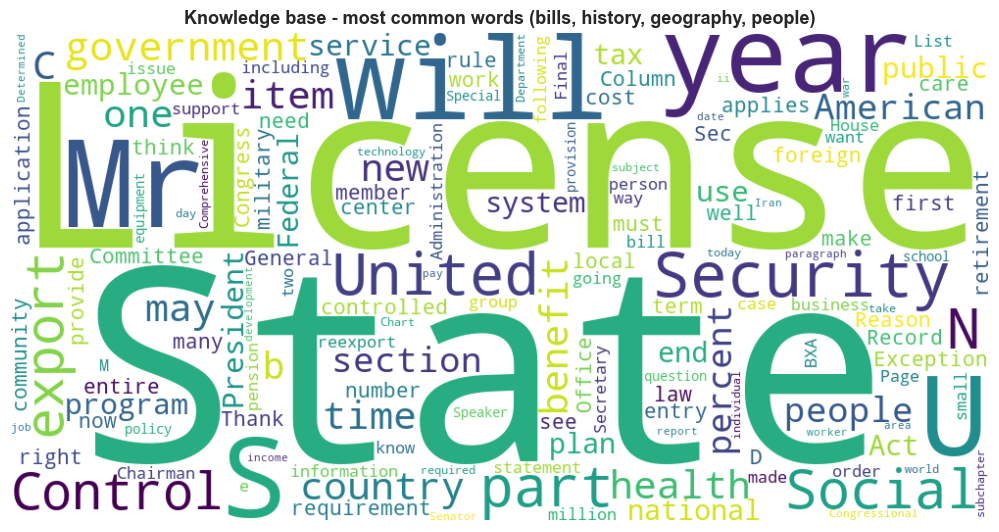

In [147]:
# Word cloud for the whole knowledge base (sampled across the plotted folders)
kb_text = " ".join(sample_folder_text(folder, sample_size=200) for folder in PLOT_FOLDERS)
plot_wordcloud(kb_text, "Knowledge base - most common words (bills, history, geography, people)")

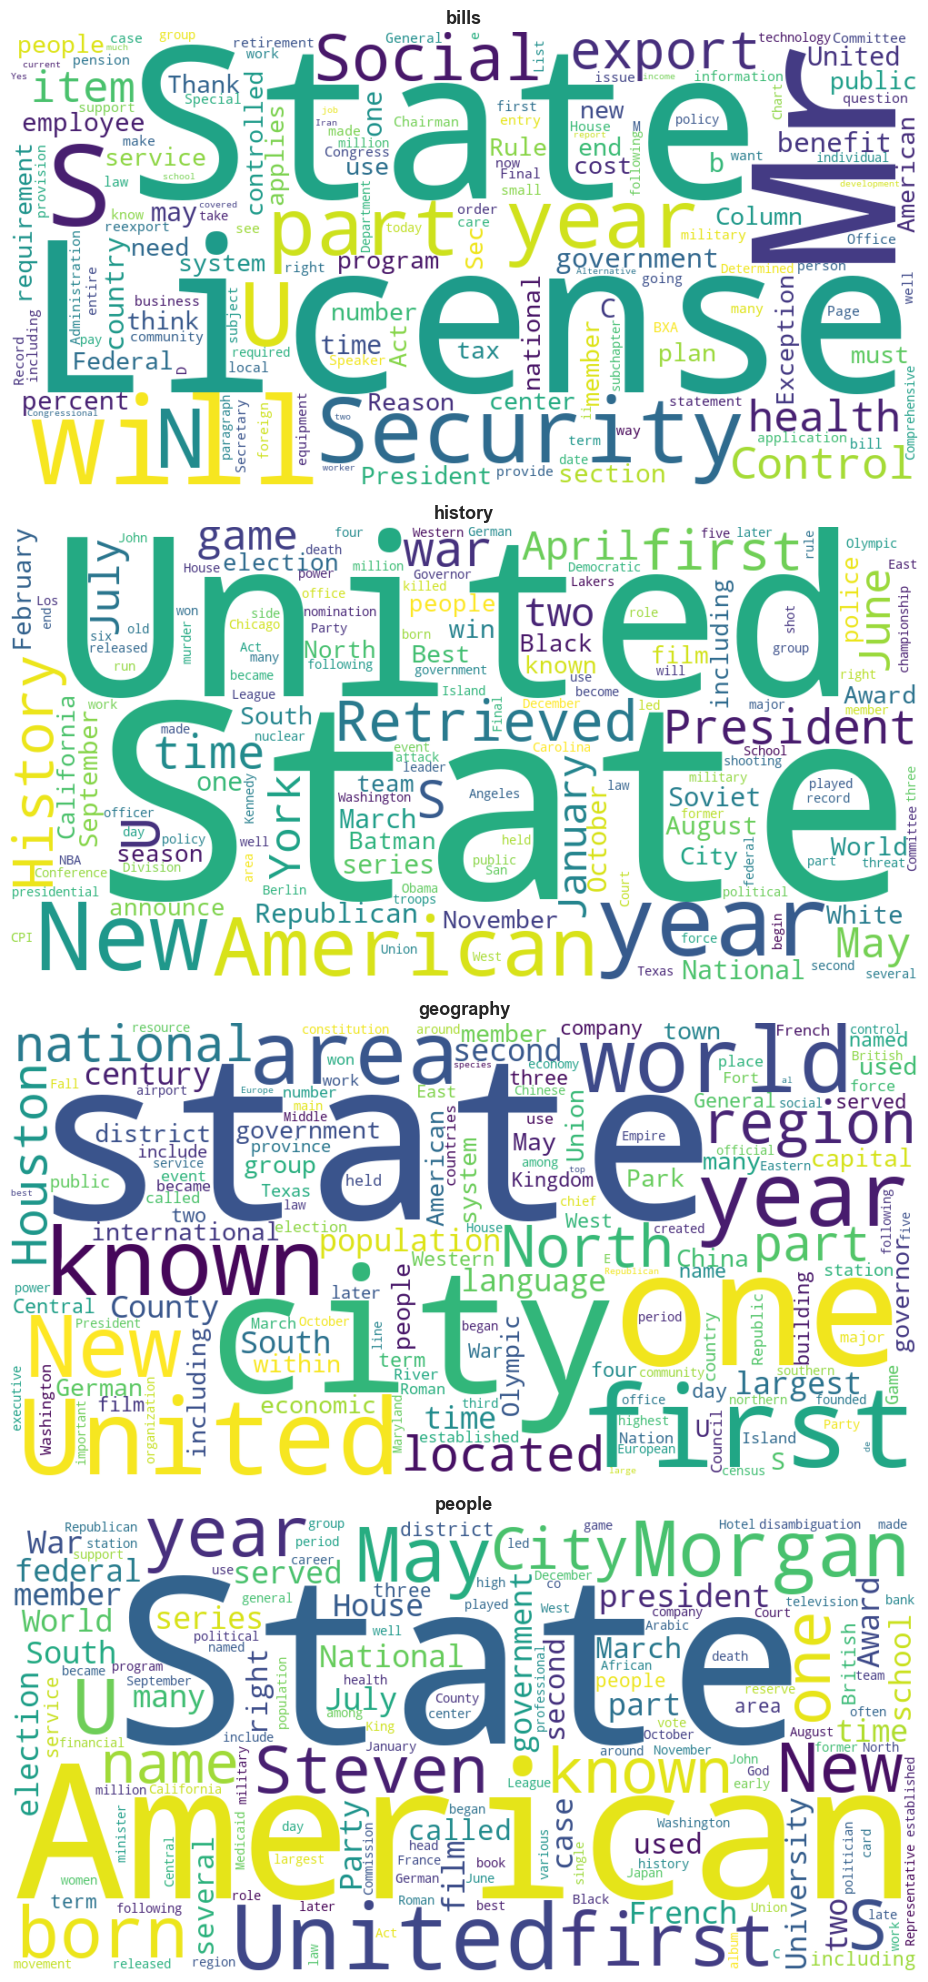

In [148]:
# Word cloud per individual folder
fig, axes = plt.subplots(len(PLOT_FOLDERS), 1, figsize=(11, 5 * len(PLOT_FOLDERS)))
if len(PLOT_FOLDERS) == 1:
    axes = [axes]

for ax, folder in zip(axes, PLOT_FOLDERS):
    text = sample_folder_text(folder, sample_size=200)
    plot_wordcloud(text, folder, ax=ax)

plt.tight_layout()
plt.show()